# Day 2: Leakage Fix, Real-World Test, Grad-CAM, Demo App and Web Export
**Project:** Food Quality & Waste Reduction using Deep Learning (SDG 2 · SDG 13 · SDG 3)

### Motivation
Day 1 gave **99.93%** test accuracy. That's suspiciously high. Test file names look like `saltandpepper_Screen Shot ... .png`, which means the dataset creator made extra copies of each photo (rotated, flipped, noisy). If copies of the **same photo** ended up in both train and test, the model was partly tested on photos it had already seen. That inflates accuracy, and it's called **data leakage**. This notebook checks it, fixes it, then tests the model on real phone photos.

### Contents
| Part | Output |
|---|---|
| **A.** Leakage check | How many test images are copies of training photos |
| **B.** Leak-free retraining | New split where all copies of one photo stay together → honest accuracy + "before vs after" table |
| **C.** Real-world test | Accuracy on real phone photos |
| **D.** Grad-CAM | Heatmaps showing *where* the model looks |
| **E.** Demo app | Gradio web app: input → preprocessing → prediction → output |
| **F.** Web export | ONNX model that runs the same pipeline in the browser, with no server |

**Environment:** Google Colab with a T4 GPU runtime. Trained models are saved to Drive, so finished training is detected and skipped on a re-run.

## Step 1: Install, import, GPU check
**What:** installs **Gradio** (for the demo app) and **pillow-heif** (so iPhone `.HEIC` photos open), then loads libraries and checks the GPU.

In [18]:
!pip install -q gradio pillow-heif kagglehub

import os, re, json, random, time, copy, hashlib, shutil
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

try:
    from pillow_heif import register_heif_opener
    register_heif_opener()                      # lets PIL open iPhone .HEIC photos
except Exception as e:
    print("pillow-heif not available (only matters for iPhone HEIC photos):", e)

IMG_EXT  = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
REAL_EXT = IMG_EXT | {'.heic', '.heif'}

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)
if device.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))
else:
    print("\n⚠️  NO GPU! Runtime -> Change runtime type -> T4 GPU, then re-run this cell.")

PyTorch: 2.14.1+cu130 | Device: cuda
GPU    : Tesla T4


## Step 2: Connect Google Drive + create the real-photo folders
**What:** connects the same Drive folder as Day 1 (`MyDrive/fruit_freshness_project/`) and creates one folder per class for the real phone photos:
`real_photos/freshapples`, `freshbanana`, `freshoranges`, `rottenapples`, `rottenbanana`, `rottenoranges`.

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    OUT = Path('/content/drive/MyDrive/fruit_freshness_project')
except Exception:
    OUT = Path('fruit_freshness_project')        # not on Colab (e.g. Kaggle / local)

FIG, RES, MOD, REAL = OUT / 'figures', OUT / 'results', OUT / 'models', OUT / 'real_photos'
EXPECTED_CLASSES = ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
for d in [FIG, RES, MOD] + [REAL / c for c in EXPECTED_CLASSES]:
    d.mkdir(parents=True, exist_ok=True)

CKPT_DAY1    = MOD / 'best_mobilenetv2.pt'              # Day 1 model (original Kaggle split)
CKPT_LF      = MOD / 'best_mobilenetv2_leakfree.pt'     # Day 2 model (leak-free split)
CKPT_BASE_LF = MOD / 'baseline_cnn_leakfree.pt'         # Day 2 baseline CNN
TIME_JSON    = RES / 'leakfree_train_time.json'         # also marks which trainings finished

print("Project folder  :", OUT)
print("Day 1 model     :", "found ✅" if CKPT_DAY1.exists() else "NOT found ❌")
print("Photo folders   :", REAL)

Mounted at /content/drive
Project folder  : /content/drive/MyDrive/fruit_freshness_project
Day 1 model     : found ✅
Photo folders   : /content/drive/MyDrive/fruit_freshness_project/real_photos


## Step 3: Download the dataset
Same dataset as Day 1.

In [3]:
import kagglehub
DATA_ROOT = kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification")

def find_split_dir(root, split_name):
    for dirpath, dirnames, _ in os.walk(root):
        if Path(dirpath).name.lower() == split_name:
            subs = [d.lower() for d in dirnames]
            if sum(('fresh' in d) or ('rotten' in d) for d in subs) >= 4:
                return Path(dirpath)
    return None

TRAIN_DIR, TEST_DIR = find_split_dir(DATA_ROOT, "train"), find_split_dir(DATA_ROOT, "test")
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)
assert TRAIN_DIR and TEST_DIR, "Could not find train/test folders"

TRAIN_DIR: /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset/train
TEST_DIR : /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset/test


# Part A: Is there data leakage?

## Step 4: Leakage check
**What it checks, in two ways:**
1. **Same original photo:** strips the copy prefix from each file name (`saltandpepper_`, `rotated_by_15_`, `vertical_flip_` …) to get the original photo's name. If a test image's original also appears in train, it's leaked.
2. **Exact duplicates:** computes an MD5 fingerprint of every file. Byte-identical files in train and test are leaked too.

**Why:** a test set is only meaningful if it contains images the model has *never* seen. Copies of a training photo (rotated, flipped or with added noise) are still the same photo, so testing on them measures memory, not generalisation.

In [4]:
def list_images(folder):
    return sorted(p for p in Path(folder).rglob('*') if p.is_file() and p.suffix.lower() in IMG_EXT)

train_files, test_files = list_images(TRAIN_DIR), list_images(TEST_DIR)
print(f"Files: {len(train_files)} in train/, {len(test_files)} in test/")

AUG_PREFIX = re.compile(r'^((rotated_by_\d+|rotated|translation|translated|vertical_flip|horizontal_flip|'
                        r'flipped|flip|saltandpepper|salt_and_pepper|noise|noisy)_)+', re.I)

def original_key(name):
    # Name of the ORIGINAL photo a file was made from, e.g.
    # 'saltandpepper_Screen Shot 2018-06-13 at 12.10.53 AM.png' -> 'screen shot 2018-06-13 at 12.10.53 am.png'
    low = name.lower()
    m = re.search(r'screen ?shot.*$', low)
    return m.group(0) if m else AUG_PREFIX.sub('', low)

def aug_prefix(name):
    pre = name[: len(name) - len(original_key(name))]
    return pre if pre else '(original photo)'

def file_md5(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

print("\nCopy types inside train/ (from file-name prefixes):")
for k, v in Counter(aug_prefix(p.name) for p in train_files).most_common(15):
    print(f"   {v:5d}  {k}")

t0 = time.time()
MD5 = {p: file_md5(p) for p in train_files + test_files}
print(f"\nFingerprinted {len(MD5)} files in {time.time() - t0:.0f}s")

train_by_key = defaultdict(list)
for p in train_files:
    train_by_key[(p.parent.name, original_key(p.name))].append(p)
train_md5 = {MD5[p] for p in train_files}

leak_name  = {p for p in test_files if (p.parent.name, original_key(p.name)) in train_by_key}
leak_exact = {p for p in test_files if MD5[p] in train_md5}
leaked     = leak_name | leak_exact
LEAK_PCT   = 100 * len(leaked) / len(test_files)
clean_test_files = [p for p in test_files if p not in leaked]
n_originals = len({(p.parent.name, original_key(p.name)) for p in train_files + test_files})

print(f"\nTotal files: {len(train_files) + len(test_files)}  |  distinct ORIGINAL photos: {n_originals}")
print(f"Test images whose original photo is also in train : {len(leak_name):5d} ({100 * len(leak_name) / len(test_files):.1f}%)")
print(f"Test images byte-identical to a train image       : {len(leak_exact):5d} ({100 * len(leak_exact) / len(test_files):.1f}%)")
print(f"Test images LEAKED (either way)                   : {len(leaked):5d} ({LEAK_PCT:.1f}%)")
print(f"Test images never seen in training in any form    : {len(clean_test_files):5d}")

json.dump(dict(train_files=len(train_files), test_files=len(test_files), distinct_original_photos=n_originals,
               test_same_original_in_train=len(leak_name), test_exact_copy_in_train=len(leak_exact),
               test_leaked_total=len(leaked), test_leaked_pct=round(LEAK_PCT, 2),
               test_never_seen=len(clean_test_files)),
          open(RES / 'leakage_check.json', 'w'), indent=2)

FORCE_RETRAIN = False     # set True to retrain on the leak-free split even if little leakage is found
DO_RETRAIN = LEAK_PCT > 1.0 or FORCE_RETRAIN
print("\nVERDICT:", "⚠️  DATA LEAKAGE FOUND -> Part B retrains on a leak-free split." if LEAK_PCT > 1.0
      else "✅ No meaningful leakage -> Day 1 results are honest. Part B will be skipped.")

Files: 10901 in train/, 2698 in test/

Copy types inside train/ (from file-name prefixes):
    1240  rotated_by_15_
    1232  translation_
    1224  rotated_by_60_
    1217  rotated_by_30_
    1208  rotated_by_45_
    1205  saltandpepper_
    1198  rotated_by_75_
    1195  vertical_flip_
    1182  (original photo)

Fingerprinted 13599 files in 97s

Total files: 13599  |  distinct ORIGINAL photos: 1511
Test images whose original photo is also in train :  2698 (100.0%)
Test images byte-identical to a train image       :     0 (0.0%)
Test images LEAKED (either way)                   :  2698 (100.0%)
Test images never seen in training in any form    :     0

VERDICT: ⚠️  DATA LEAKAGE FOUND -> Part B retrains on a leak-free split.


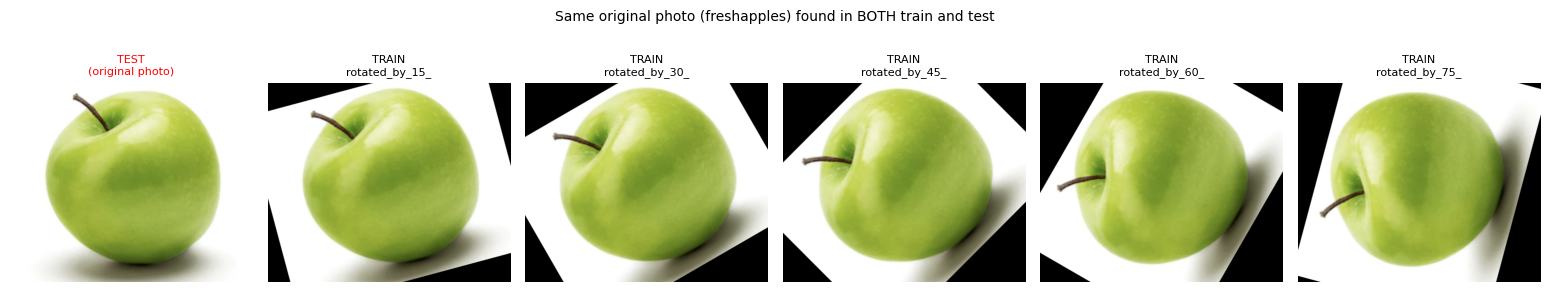

In [5]:
# Figure: the SAME original photo appearing in both train and test
example = None
for p in sorted(leak_name):
    sibs = train_by_key[(p.parent.name, original_key(p.name))]
    if len(sibs) >= 3:
        example = (p, sibs[:5]); break
if example is None and leak_name:
    p = sorted(leak_name)[0]
    example = (p, train_by_key[(p.parent.name, original_key(p.name))][:5])

if example:
    test_p, sibs = example
    imgs = [(test_p, 'TEST')] + [(s, 'TRAIN') for s in sibs]
    fig, axes = plt.subplots(1, len(imgs), figsize=(2.6 * len(imgs), 3.3))
    for a, (p, where) in zip(np.atleast_1d(axes), imgs):
        a.imshow(Image.open(p).convert('RGB')); a.axis('off')
        a.set_title(f"{where}\n{aug_prefix(p.name)[:24]}", fontsize=8, color='red' if where == 'TEST' else 'black')
    plt.suptitle(f"Same original photo ({test_p.parent.name}) found in BOTH train and test", fontsize=10)
    plt.tight_layout(); plt.savefig(FIG / 'leakage_example.png', dpi=200); plt.show()
else:
    print("No name-based leakage to show.")

# Part B: Fix the leakage and retrain

## Step 5: Group-aware split (the fix)
**What:**
1. Merge `train/` and `test/` into one pool.
2. **Group** every file with all other copies of the same original photo (same original name *or* identical bytes).
3. Split the **groups**, not the files: **70% train / 15% validation / 15% test**, separately for each class (stratified).
4. Prove that no original photo is shared between splits.

**Why:** all images derived from the same original photograph are assigned to the same subset, so no photo can leak between splits. The dataset's built-in copies still help, because inside the training split they act as extra augmentation.

In [6]:
all_files = train_files + test_files
CLASS_NAMES = sorted({p.parent.name for p in all_files})
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)
if CLASS_NAMES != EXPECTED_CLASSES:
    print("⚠️ Class names differ from the expected ones - creating matching photo folders too.")
    for c in CLASS_NAMES:
        (REAL / c).mkdir(parents=True, exist_ok=True)

# 1) Group files: same original photo (per class) OR identical bytes -> same group (union-find)
parent = list(range(len(all_files)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

first_seen = {}
for i, p in enumerate(all_files):
    for key in (('name', p.parent.name, original_key(p.name)), ('md5', MD5[p])):
        if key in first_seen:
            ra, rb = find(first_seen[key]), find(i)
            if ra != rb:
                parent[rb] = ra
        else:
            first_seen[key] = i

groups = defaultdict(list)
for i in range(len(all_files)):
    groups[find(i)].append(i)
sizes = [len(m) for m in groups.values()]
print(f"{len(all_files)} files -> {len(groups)} groups (original photos). "
      f"Copies per photo: median {int(np.median(sizes))}, max {max(sizes)}")

# 2) Split the GROUPS 70/15/15 inside each class
rng = random.Random(SEED)
groups_by_class = defaultdict(list)
for gid, members in groups.items():
    majority = Counter(all_files[i].parent.name for i in members).most_common(1)[0][0]
    groups_by_class[majority].append(gid)

split_of_group = {}
for c in CLASS_NAMES:
    gids = sorted(groups_by_class[c]); rng.shuffle(gids)
    total, done = sum(len(groups[g]) for g in gids), 0
    for g in gids:
        frac = done / total
        split_of_group[g] = 'train' if frac < 0.70 else ('val' if frac < 0.85 else 'test')
        done += len(groups[g])

rows = []
for gid, members in groups.items():
    for i in members:
        p = all_files[i]
        rows.append({'path': str(p), 'class': p.parent.name, 'label': CLASS_NAMES.index(p.parent.name),
                     'split': split_of_group[gid], 'group': gid,
                     'kaggle_folder': 'train' if i < len(train_files) else 'test'})
split_df = pd.DataFrame(rows)
split_df.to_csv(RES / 'leakfree_split.csv', index=False)

# 3) Proof: nothing shared between splits
for what, keyfun in (('original photos', lambda s: (Path(s).parent.name, original_key(Path(s).name))),
                     ('identical files', lambda s: MD5[Path(s)])):
    keys = {s: {keyfun(p) for p in split_df.loc[split_df['split'] == s, 'path']} for s in ('train', 'val', 'test')}
    shared = len(keys['train'] & keys['val']) + len(keys['train'] & keys['test']) + len(keys['val'] & keys['test'])
    print(f"Shared {what} between splits: {shared}  {'✅' if shared == 0 else '❌'}")

counts = pd.crosstab(split_df['class'], split_df['split'])[['train', 'val', 'test']]
counts.loc['TOTAL'] = counts.sum()
print(counts)
counts.to_csv(RES / 'leakfree_split_counts.csv')

Classes: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
13599 files -> 1511 groups (original photos). Copies per photo: median 9, max 9
Shared original photos between splits: 0  ✅
Shared identical files between splits: 0  ✅
split          train   val  test
class                           
freshapples     1467   315   306
freshbanana     1377   297   288
freshoranges    1305   279   270
rottenapples    2061   441   441
rottenbanana    1935   414   405
rottenoranges   1404   297   297
TOTAL           9549  2043  2007


## Step 6: Preprocessing (same as Day 1) + helpers
Same transforms as Day 1, so the only thing that changes is the split. That makes the before/after comparison fair.

`display_tf` is the resize-and-crop *without* normalisation. It shows exactly what the model sees, and the demo app uses it to display the preprocessing step.

In [7]:
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),   # no hue/saturation jitter: colour = freshness signal
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
display_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(IMG_SIZE)])

def load_photo(path):
    # Open any image (incl. phone photos) upright and in RGB
    img = Image.open(path)
    try:
        img = ImageOps.exif_transpose(img)     # phone photos store their rotation in EXIF
    except Exception:
        pass
    return img.convert('RGB')

class FruitDataset(Dataset):
    def __init__(self, items, transform):
        self.items, self.transform = items, transform      # items = [(path, label), ...]
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, label = self.items[i]
        with Image.open(path) as im:
            img = im.convert('RGB')
        return self.transform(img), label

## Step 7: Model, training, evaluation and Grad-CAM functions
These are the same model and training code as Day 1 (MobileNetV2 + two-phase training, plus the custom CNN baseline), with a few helpers added:
- `load_model`: loads a saved model from Drive.
- `compute_metrics`: accuracy, macro precision/recall/F1, and fresh-vs-rotten metrics.
- `gradcam` / `overlay_cam`: heatmaps, explained in Step 14.

In [9]:
def build_mobilenet(num_classes, pretrained=True, freeze=True):
    weights = models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.mobilenet_v2(weights=weights)
    if freeze:
        for p in model.features.parameters():
            p.requires_grad = False
    model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.classifier[1].in_features, num_classes))
    return model

class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.head(self.pool(self.features(x)))

def count_params(model):
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)

criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None, backbone_frozen=False):
    training = optimizer is not None
    model.train(training)
    if training and backbone_frozen and hasattr(model, 'features'):
        model.features.eval()   # keep frozen BatchNorm statistics fixed
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def save_checkpoint(model, path, arch):
    torch.save({'arch': arch, 'model_state': model.state_dict(), 'class_names': CLASS_NAMES,
                'img_size': IMG_SIZE, 'mean': MEAN, 'std': STD}, path)

def fit(model, optimizer, epochs, phase, history, best, ckpt_path, arch,
        scheduler=None, patience=3, backbone_frozen=False):
    bad_epochs = 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, backbone_frozen)
        va_loss, va_acc = run_epoch(model, val_loader)
        if scheduler is not None:
            scheduler.step(va_loss)
        history.append(dict(phase=phase, epoch=len(history) + 1, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc, lr=optimizer.param_groups[0]['lr'],
                            seconds=round(time.time() - t0, 1)))
        flag = ''
        if va_loss < best['val_loss']:
            best.update(val_loss=va_loss, val_acc=va_acc, state=copy.deepcopy(model.state_dict()))
            save_checkpoint(model, ckpt_path, arch)
            bad_epochs, flag = 0, '  ✓ saved'
        else:
            bad_epochs += 1
        print(f"[{phase}] epoch {ep}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time() - t0:.0f}s{flag}")
        if bad_epochs >= patience:
            print(f"Early stopping: no val-loss improvement for {patience} epochs.")
            break

@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    ys, ps, probs = [], [], []
    for x, y in loader:
        pr = model(x.to(device)).softmax(1).cpu()
        probs.append(pr); ps.append(pr.argmax(1)); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()

@torch.no_grad()
def predict_pil(model, img):
    model.eval()
    return model(eval_tf(img).unsqueeze(0).to(device)).softmax(1)[0].cpu().numpy()

def compute_metrics(y_true, y_pred, class_names, name):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    is_rotten = np.array(['rotten' in c.lower() for c in class_names]).astype(int)
    bt, bp = is_rotten[y_true], is_rotten[y_pred]
    rp, rr, rf, _ = precision_recall_fscore_support(bt, bp, average='binary', pos_label=1, zero_division=0)
    return {'model': name, 'accuracy': accuracy_score(y_true, y_pred), 'macro_precision': p, 'macro_recall': r,
            'macro_f1': f1, 'fresh_vs_rotten_accuracy': accuracy_score(bt, bp), 'rotten_precision': rp,
            'rotten_recall': rr, 'rotten_f1': rf, 'n_images': int(len(y_true))}

def rounded(d):
    return {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}

def print_metrics(m):
    for k, v in m.items():
        print(f"{k:26s}: {v:.4f}" if isinstance(v, (float, np.floating)) else f"{k:26s}: {v}")

def update_json(path, **kw):
    d = json.load(open(path)) if Path(path).exists() else {}
    d.update(kw)
    json.dump(d, open(path, 'w'), indent=2)

def load_model(ckpt_path):
    ck = torch.load(ckpt_path, map_location=device)
    n = len(ck['class_names'])
    if ck['arch'] == 'mobilenet_v2':
        m = build_mobilenet(n, pretrained=False, freeze=False)
    elif ck['arch'] == 'simple_cnn':
        m = SimpleCNN(n)
    else:
        raise ValueError(f"Unknown architecture {ck['arch']}")
    m.load_state_dict(ck['model_state'])
    return m.to(device).eval(), ck

# ---------- Grad-CAM (explained in Step 14) ----------
JET = matplotlib.colormaps['jet']

def gradcam(model, img):
    # Returns (class probabilities, predicted index, 7x7 heatmap in [0, 1]) for a MobileNetV2 model
    model.eval()
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.enable_grad():
        feats = model.features(x)                                         # [1, 1280, 7, 7] last conv feature maps
        logits = model.classifier(torch.flatten(F.adaptive_avg_pool2d(feats, 1), 1))
        pred = int(logits.argmax(1))
        grads = torch.autograd.grad(logits[0, pred], feats)[0]            # d(class score) / d(feature maps)
    weights = grads.mean(dim=(2, 3), keepdim=True)                        # one importance weight per feature map
    cam = F.relu((weights * feats).sum(dim=1))[0]                         # weighted sum, keep positive evidence
    cam = (cam / (cam.max() + 1e-8)).detach().cpu().numpy()
    probs = logits.softmax(1)[0].detach().cpu().numpy()
    return probs, pred, cam

def overlay_cam(img, cam, alpha=0.45):
    base = np.asarray(display_tf(img), dtype=np.float32) / 255.0
    cam_big = Image.fromarray(np.uint8(255 * cam)).resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
    heat = JET(np.asarray(cam_big, dtype=np.float32) / 255.0)[..., :3]
    return Image.fromarray(np.uint8(255 * np.clip((1 - alpha) * base + alpha * heat, 0, 1)))

## Step 8: Data loaders for the leak-free split

In [10]:
splits = {s: [(p, int(l)) for p, l in zip(split_df.loc[split_df['split'] == s, 'path'],
                                          split_df.loc[split_df['split'] == s, 'label'])]
          for s in ('train', 'val', 'test')}

BATCH_SIZE = 32
train_loader = DataLoader(FruitDataset(splits['train'], train_tf), batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(FruitDataset(splits['val'],   eval_tf),  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(FruitDataset(splits['test'],  eval_tf),  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print("Leak-free split sizes:", {s: len(v) for s, v in splits.items()})

Leak-free split sizes: {'train': 9549, 'val': 2043, 'test': 2007}


## Step 9: Retrain MobileNetV2 on the leak-free split
This uses the exact same recipe as Day 1: phase 1 trains the head only (4 epochs, lr 1e-3), then phase 2 fine-tunes `features[14:]` (up to 8 epochs, lr 1e-4) with early stopping.
**Only runs if Step 4 found leakage.** If a *finished* leak-free model is already in Drive, training is skipped.

In [11]:
RETRAIN_AGAIN = False   # True = train again even if a finished leak-free model is already saved in Drive
train_info = json.load(open(TIME_JSON)) if TIME_JSON.exists() else {}

if not DO_RETRAIN:
    print("Skipped: no leakage found, so the Day 1 model is used.")
elif CKPT_LF.exists() and 'mobilenet_minutes' in train_info and not RETRAIN_AGAIN:
    print(f"Already trained earlier ({train_info['mobilenet_minutes']} min) and saved in Drive, so skipping. "
          "Set RETRAIN_AGAIN = True to train again.")
else:
    train_info.pop('mobilenet_minutes', None)          # mark as 'not finished' until training completes
    json.dump(train_info, open(TIME_JSON, 'w'), indent=2)
    seed_everything()
    model = build_mobilenet(NUM_CLASSES).to(device)
    history, best = [], {'val_loss': float('inf')}
    t_start = time.time()

    opt1 = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
    fit(model, opt1, 4, 'phase1', history, best, CKPT_LF, 'mobilenet_v2', backbone_frozen=True)

    model.load_state_dict(best['state'])
    for p in model.features[14:].parameters():
        p.requires_grad = True
    opt2 = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)
    sched2 = torch.optim.lr_scheduler.ReduceLROnPlateau(opt2, mode='min', factor=0.3, patience=1)
    fit(model, opt2, 8, 'phase2', history, best, CKPT_LF, 'mobilenet_v2', scheduler=sched2, patience=3)

    minutes = (time.time() - t_start) / 60
    pd.DataFrame(history).to_csv(RES / 'leakfree_training_history.csv', index=False)
    update_json(TIME_JSON, mobilenet_minutes=round(minutes, 1))
    print(f"\nDone in {minutes:.1f} min | best val acc {best['val_acc']:.4f} | saved to {CKPT_LF.name}")

Already trained earlier (17.2 min) and saved in Drive, so skipping. Set RETRAIN_AGAIN = True to train again.


## Step 10: Retrain the baseline CNN on the leak-free split
This keeps the "custom CNN vs MobileNetV2" comparison fair on the new split.

In [12]:
RUN_BASELINE = True
train_info = json.load(open(TIME_JSON)) if TIME_JSON.exists() else {}
if not (DO_RETRAIN and RUN_BASELINE):
    print("Skipped.")
elif CKPT_BASE_LF.exists() and 'baseline_minutes' in train_info and not RETRAIN_AGAIN:
    print("Baseline already trained earlier and saved in Drive, so skipping.")
else:
    train_info.pop('baseline_minutes', None)
    json.dump(train_info, open(TIME_JSON, 'w'), indent=2)
    seed_everything()
    base = SimpleCNN(NUM_CLASSES).to(device)
    b_hist, b_best = [], {'val_loss': float('inf')}
    t0 = time.time()
    fit(base, torch.optim.Adam(base.parameters(), lr=1e-3), 8, 'baseline', b_hist, b_best,
        CKPT_BASE_LF, 'simple_cnn', patience=3)
    update_json(TIME_JSON, baseline_minutes=round((time.time() - t0) / 60, 1))

[baseline] epoch 1/8 | train loss 0.6069 acc 0.7934 | val loss 0.6702 acc 0.7685 | 113s  ✓ saved
[baseline] epoch 2/8 | train loss 0.4211 acc 0.8549 | val loss 0.4357 acc 0.8527 | 105s  ✓ saved
[baseline] epoch 3/8 | train loss 0.3580 acc 0.8752 | val loss 0.3642 acc 0.8967 | 101s  ✓ saved
[baseline] epoch 4/8 | train loss 0.3189 acc 0.8840 | val loss 0.3576 acc 0.8742 | 103s  ✓ saved
[baseline] epoch 5/8 | train loss 0.2913 acc 0.8959 | val loss 0.2726 acc 0.9139 | 103s  ✓ saved
[baseline] epoch 6/8 | train loss 0.2706 acc 0.9018 | val loss 0.3946 acc 0.8708 | 102s
[baseline] epoch 7/8 | train loss 0.2593 acc 0.9115 | val loss 0.2758 acc 0.9163 | 101s
[baseline] epoch 8/8 | train loss 0.2296 acc 0.9159 | val loss 0.3458 acc 0.8997 | 102s
Early stopping: no val-loss improvement for 3 epochs.


## Step 11: Honest results on the leak-free test set
**What:** evaluates the saved leak-free models on the new test set, which contains only photos never seen in any form during training. You get:
- the classification report, metrics, confusion matrix, training curves and mistakes (same as Day 1)
- a **comparison table**: MobileNetV2 vs custom CNN
- a **leakage-effect table**: Day 1 (leaky split) vs Day 2 (leak-free split), showing how much the leakage inflated the original results.

               precision    recall  f1-score   support

  freshapples     0.9903    1.0000    0.9951       306
  freshbanana     1.0000    0.9861    0.9930       288
 freshoranges     0.9818    1.0000    0.9908       270
 rottenapples     0.9955    0.9932    0.9943       441
 rottenbanana     1.0000    1.0000    1.0000       405
rottenoranges     1.0000    0.9899    0.9949       297

     accuracy                         0.9950      2007
    macro avg     0.9946    0.9949    0.9947      2007
 weighted avg     0.9951    0.9950    0.9950      2007

model                     : MobileNetV2 (transfer learning)
accuracy                  : 0.9950
macro_precision           : 0.9946
macro_recall              : 0.9949
macro_f1                  : 0.9947
fresh_vs_rotten_accuracy  : 0.9980
rotten_precision          : 1.0000
rotten_recall             : 0.9965
rotten_f1                 : 0.9982
n_images                  : 2007


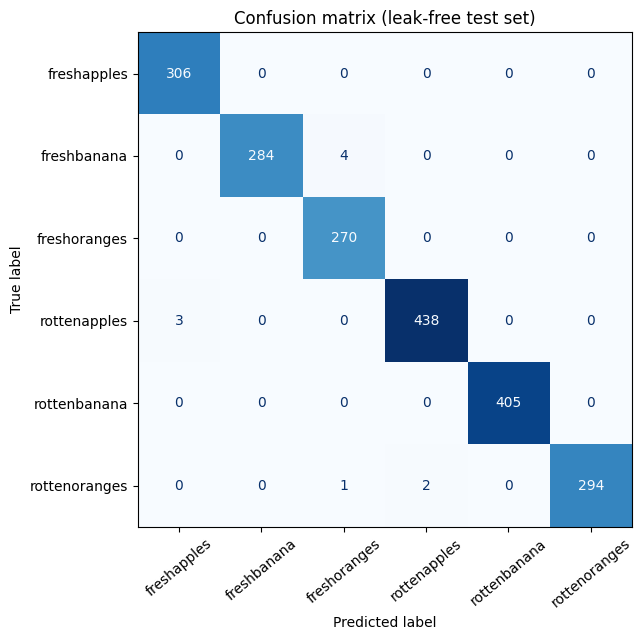

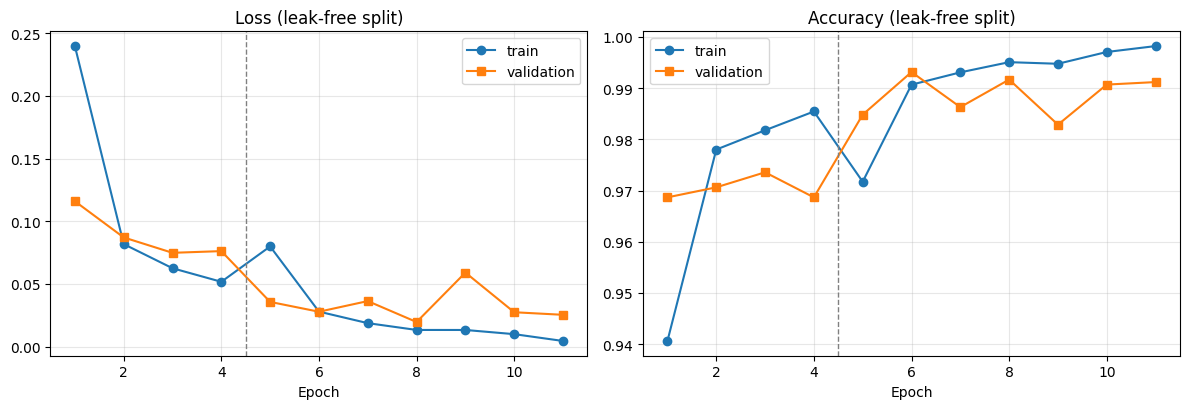

In [13]:
m_mn = m_base = None
if CKPT_LF.exists() and 'test_loader' in globals():
    mn_model, _ = load_model(CKPT_LF)
    y_true, y_pred, y_prob = predict_loader(mn_model, test_loader)
    m_mn = compute_metrics(y_true, y_pred, CLASS_NAMES, 'MobileNetV2 (transfer learning)')
    report_txt = classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES,
                                       digits=4, zero_division=0)
    print(report_txt); print_metrics(m_mn)
    (RES / 'leakfree_classification_report.txt').write_text(report_txt)
    json.dump(rounded(m_mn), open(RES / 'leakfree_test_metrics.json', 'w'), indent=2)

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', xticks_rotation=40,
                                                                colorbar=False, values_format='d')
    ax.set_title('Confusion matrix (leak-free test set)')
    plt.tight_layout(); plt.savefig(FIG / 'leakfree_confusion_matrix.png', dpi=200); plt.show()

    hist_path = RES / 'leakfree_training_history.csv'
    if hist_path.exists():
        h = pd.read_csv(hist_path)
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
        a1.plot(h['epoch'], h['train_loss'], 'o-', label='train'); a1.plot(h['epoch'], h['val_loss'], 's-', label='validation')
        a2.plot(h['epoch'], h['train_acc'], 'o-', label='train');  a2.plot(h['epoch'], h['val_acc'], 's-', label='validation')
        p2 = h.loc[h['phase'] == 'phase2', 'epoch']
        for a, t in ((a1, 'Loss'), (a2, 'Accuracy')):
            if len(p2):
                a.axvline(p2.min() - 0.5, ls='--', c='grey', lw=1)
            a.set_title(t + ' (leak-free split)'); a.set_xlabel('Epoch'); a.legend(); a.grid(alpha=0.3)
        plt.tight_layout(); plt.savefig(FIG / 'leakfree_training_curves.png', dpi=200); plt.show()
else:
    print("No leak-free model to evaluate (no leakage found, or Step 9 didn't run).")

Misclassified: 10 / 2007


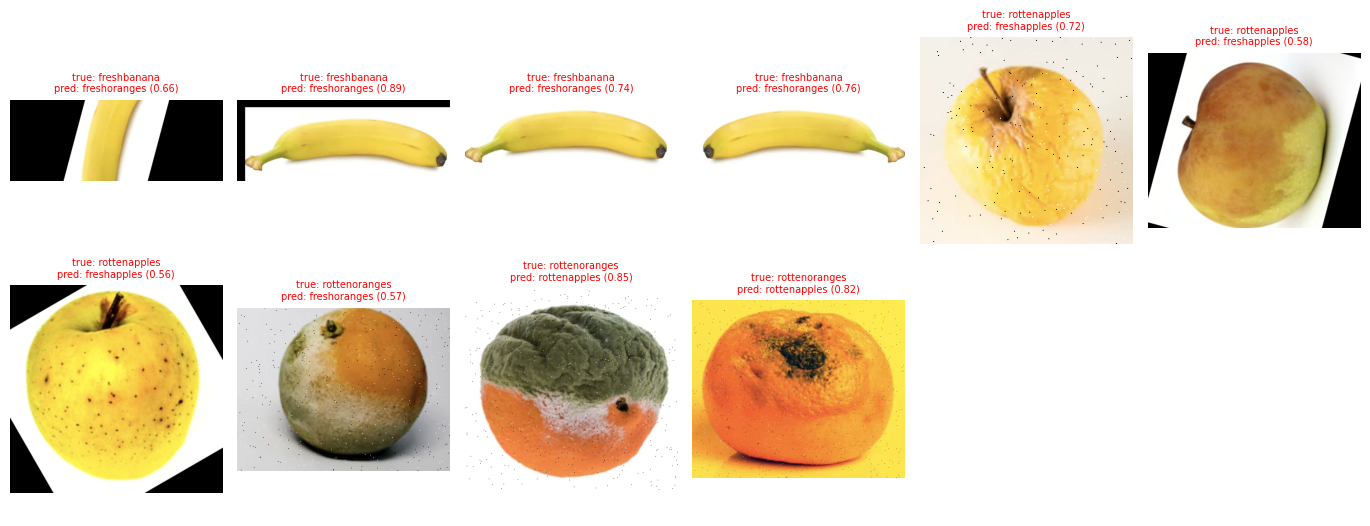

In [14]:
# Mistakes on the leak-free test set
if m_mn is not None:
    test_paths = [p for p, _ in splits['test']]
    wrong = np.where(y_true != y_pred)[0]
    print(f"Misclassified: {len(wrong)} / {len(y_true)}")
    if len(wrong):
        show = wrong[:12]
        cols = 6; rows_n = int(np.ceil(len(show) / cols))
        fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 2.3, rows_n * 2.7))
        axes = np.array(axes).reshape(-1)
        for a in axes:
            a.axis('off')
        for a, i in zip(axes, show):
            a.imshow(Image.open(test_paths[i]).convert('RGB'))
            a.set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]} ({y_prob[i].max():.2f})",
                        fontsize=7, color='red')
        plt.tight_layout(); plt.savefig(FIG / 'leakfree_misclassified.png', dpi=200); plt.show()

In [20]:
# Table 1: MobileNetV2 vs custom CNN (leak-free split)
times = json.load(open(TIME_JSON)) if TIME_JSON.exists() else {}
comp_rows = []
if m_mn is not None:
    comp_rows.append(('MobileNetV2 (transfer learning)', CKPT_LF, m_mn, times.get('mobilenet_minutes')))
if CKPT_BASE_LF.exists() and 'test_loader' in globals():
    b_model, _ = load_model(CKPT_BASE_LF)
    by, bp, _ = predict_loader(b_model, test_loader)
    m_base = compute_metrics(by, bp, CLASS_NAMES, 'Custom CNN (from scratch)')
    comp_rows.append(('Custom CNN (from scratch)', CKPT_BASE_LF, m_base, times.get('baseline_minutes')))
if comp_rows:
    comp = pd.DataFrame([{'Model': name, 'Parameters': f"{count_params(load_model(ck)[0])[0]:,}",
                          'Train time (min)': t, 'Test accuracy': round(m['accuracy'], 4),
                          'Macro F1': round(m['macro_f1'], 4), 'Rotten recall': round(m['rotten_recall'], 4)}
                         for name, ck, m, t in comp_rows])
    comp.to_csv(RES / 'leakfree_model_comparison.csv', index=False)
    print("TABLE 1: models compared on the leak-free test set"); display(comp)

# Table 2: effect of fixing the leakage
eff = []
if (RES / 'test_metrics.json').exists():
    d1 = json.load(open(RES / 'test_metrics.json'))
    eff.append({'Model': 'MobileNetV2', 'Evaluation': 'Original Kaggle split (leaky)', 'Test images': d1.get('n_test_images'),
                'Accuracy': d1.get('test_accuracy'), 'Macro F1': d1.get('macro_f1'), 'Rotten recall': d1.get('rotten_recall')})
if (RES / 'model_comparison.csv').exists():
    c1 = pd.read_csv(RES / 'model_comparison.csv')
    c1 = c1[c1['Model'].str.contains('Custom', case=False)]
    if len(c1):
        r = c1.iloc[0]
        eff.append({'Model': 'Custom CNN', 'Evaluation': 'Original Kaggle split (leaky)', 'Test images': None,
                    'Accuracy': r['Test accuracy'], 'Macro F1': r['Macro F1'], 'Rotten recall': r['Rotten recall']})
if CKPT_DAY1.exists() and globals().get('clean_test_files'):
    d1_model, _ = load_model(CKPT_DAY1)
    items = [(str(p), CLASS_NAMES.index(p.parent.name)) for p in clean_test_files]
    cy, cp, _ = predict_loader(d1_model, DataLoader(FruitDataset(items, eval_tf), batch_size=64, num_workers=2))
    mc = compute_metrics(cy, cp, CLASS_NAMES, 'day1-clean')
    eff.append({'Model': 'MobileNetV2 (Day 1 model)', 'Evaluation': 'Only Kaggle test photos never seen in training',
                'Test images': len(items), 'Accuracy': mc['accuracy'], 'Macro F1': mc['macro_f1'],
                'Rotten recall': mc['rotten_recall']})
for name, m in (('MobileNetV2', m_mn), ('Custom CNN', m_base)):
    if m is not None:
        eff.append({'Model': name, 'Evaluation': 'Leak-free group split (Day 2)', 'Test images': m['n_images'],
                    'Accuracy': m['accuracy'], 'Macro F1': m['macro_f1'], 'Rotten recall': m['rotten_recall']})
if eff:
    eff_df = pd.DataFrame(eff).round(4)
    eff_df.to_csv(RES / 'leakage_effect.csv', index=False)
    print("\nTABLE 2: effect of fixing the data leakage"); display(eff_df)

TABLE 1: models compared on the leak-free test set


,Model,Parameters,Train time (min),Test accuracy,Macro F1,Rotten recall
0,MobileNetV2 (transfer learning),"2,231,558",17.2,0.9950,0.9947,0.9965
1,Custom CNN (from scratch),"390,918",13.8,0.9003,0.9037,0.9720



TABLE 2: effect of fixing the data leakage


,Model,Evaluation,Test images,Accuracy,Macro F1,Rotten recall
0,MobileNetV2,Original Kaggle split (leaky),2698.0,0.9993,0.9993,0.9987
1,Custom CNN,Original Kaggle split (leaky),NaN,0.9396,0.9404,0.9544
2,MobileNetV2,Leak-free group split (Day 2),2007.0,0.9950,0.9947,0.9965
3,Custom CNN,Leak-free group split (Day 2),2007.0,0.9003,0.9037,0.9720


# Part C: Real-world test on phone photos

## Step 12: Load the final model
Uses the leak-free model if Part B ran, otherwise the Day 1 model. From here on, every step uses this one model.

In [27]:
FINAL_CKPT = CKPT_LF if CKPT_LF.exists() else CKPT_DAY1
assert FINAL_CKPT.exists(), "No trained model in Drive/models - run Part B (or the Day 1 notebook) first."
demo_model, ck = load_model(FINAL_CKPT)
CLASS_NAMES = ck['class_names']
NUM_CLASSES = len(CLASS_NAMES)
print("Final model:", FINAL_CKPT.name, "| classes:", CLASS_NAMES)

Final model: best_mobilenetv2_leakfree.pt | classes: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']


## Step 13: Test on real phone photos
### Photo collection protocol
- **How many:** 5–10 per class, 30–60 in total.
- **What:** **one fruit per photo**, filling most of the frame (like the dataset images).
- **Variety:** some on a plain background (table, white paper), some on a normal one (kitchen counter, market basket), with mixed angles and lighting.
- **"Rotten" means clearly spoiled:** big brown or black patches, mould, very soft or wrinkled skin. A banana with a few brown sugar spots is *ripe*, not rotten. Borderline fruit is labelled with its honest class.
- **Camera:** normal photo mode, no filters, no portrait blur.
- **No cherry-picking:** the point is to measure real-world performance honestly.

These photos are **test-only** and are never used for training.

**Why:** dataset images are clean close-ups. Real photos have different lighting, backgrounds and cameras (*domain shift*). The gap between test-set accuracy and real-photo accuracy is the honest measure of how the model would do in a real shop or food bank.

In [28]:
real_items = [(p, c) for c in CLASS_NAMES for p in sorted((REAL / c).glob('*')) if p.suffix.lower() in REAL_EXT]
print("Photos found:", {c: sum(1 for _, cc in real_items if cc == c) for c in CLASS_NAMES})

real_df, m_real = None, None
if not real_items:
    print("\nNo photos yet. Upload them into Drive -> fruit_freshness_project/real_photos/<class>/ and re-run this cell.")
    print("(If they're uploaded but not found: re-run Step 2 to refresh Drive, then this cell.)")
else:
    rows = []
    for p, c in real_items:
        try:
            probs = predict_pil(demo_model, load_photo(p))
        except Exception as e:
            print("Could not read", p.name, "-", e); continue
        k = int(probs.argmax())
        rows.append({'file': p.name, 'true': c, 'pred': CLASS_NAMES[k], 'confidence': round(float(probs[k]), 4),
                     'correct': c == CLASS_NAMES[k], 'path': str(p)})
    real_df = pd.DataFrame(rows)
    real_df.drop(columns='path').to_csv(RES / 'real_photo_predictions.csv', index=False)
    yt = [CLASS_NAMES.index(c) for c in real_df['true']]
    yp = [CLASS_NAMES.index(c) for c in real_df['pred']]
    m_real = compute_metrics(yt, yp, CLASS_NAMES, 'Final model on real phone photos')
    present = sorted(set(yt) | set(yp))
    print(classification_report(yt, yp, labels=present, target_names=[CLASS_NAMES[i] for i in present], zero_division=0))
    print_metrics(m_real)
    json.dump(rounded(m_real), open(RES / 'real_photo_metrics.json', 'w'), indent=2)

Photos found: {'freshapples': 5, 'freshbanana': 5, 'freshoranges': 5, 'rottenapples': 5, 'rottenbanana': 5, 'rottenoranges': 5}
               precision    recall  f1-score   support

  freshapples       0.83      1.00      0.91         5
  freshbanana       1.00      0.80      0.89         5
 freshoranges       1.00      1.00      1.00         5
 rottenapples       1.00      1.00      1.00         5
 rottenbanana       1.00      1.00      1.00         5
rottenoranges       1.00      1.00      1.00         5

     accuracy                           0.97        30
    macro avg       0.97      0.97      0.97        30
 weighted avg       0.97      0.97      0.97        30

model                     : Final model on real phone photos
accuracy                  : 0.9667
macro_precision           : 0.9722
macro_recall              : 0.9667
macro_f1                  : 0.9663
fresh_vs_rotten_accuracy  : 1.0000
rotten_precision          : 1.0000
rotten_recall             : 1.0000
rotten_f1    

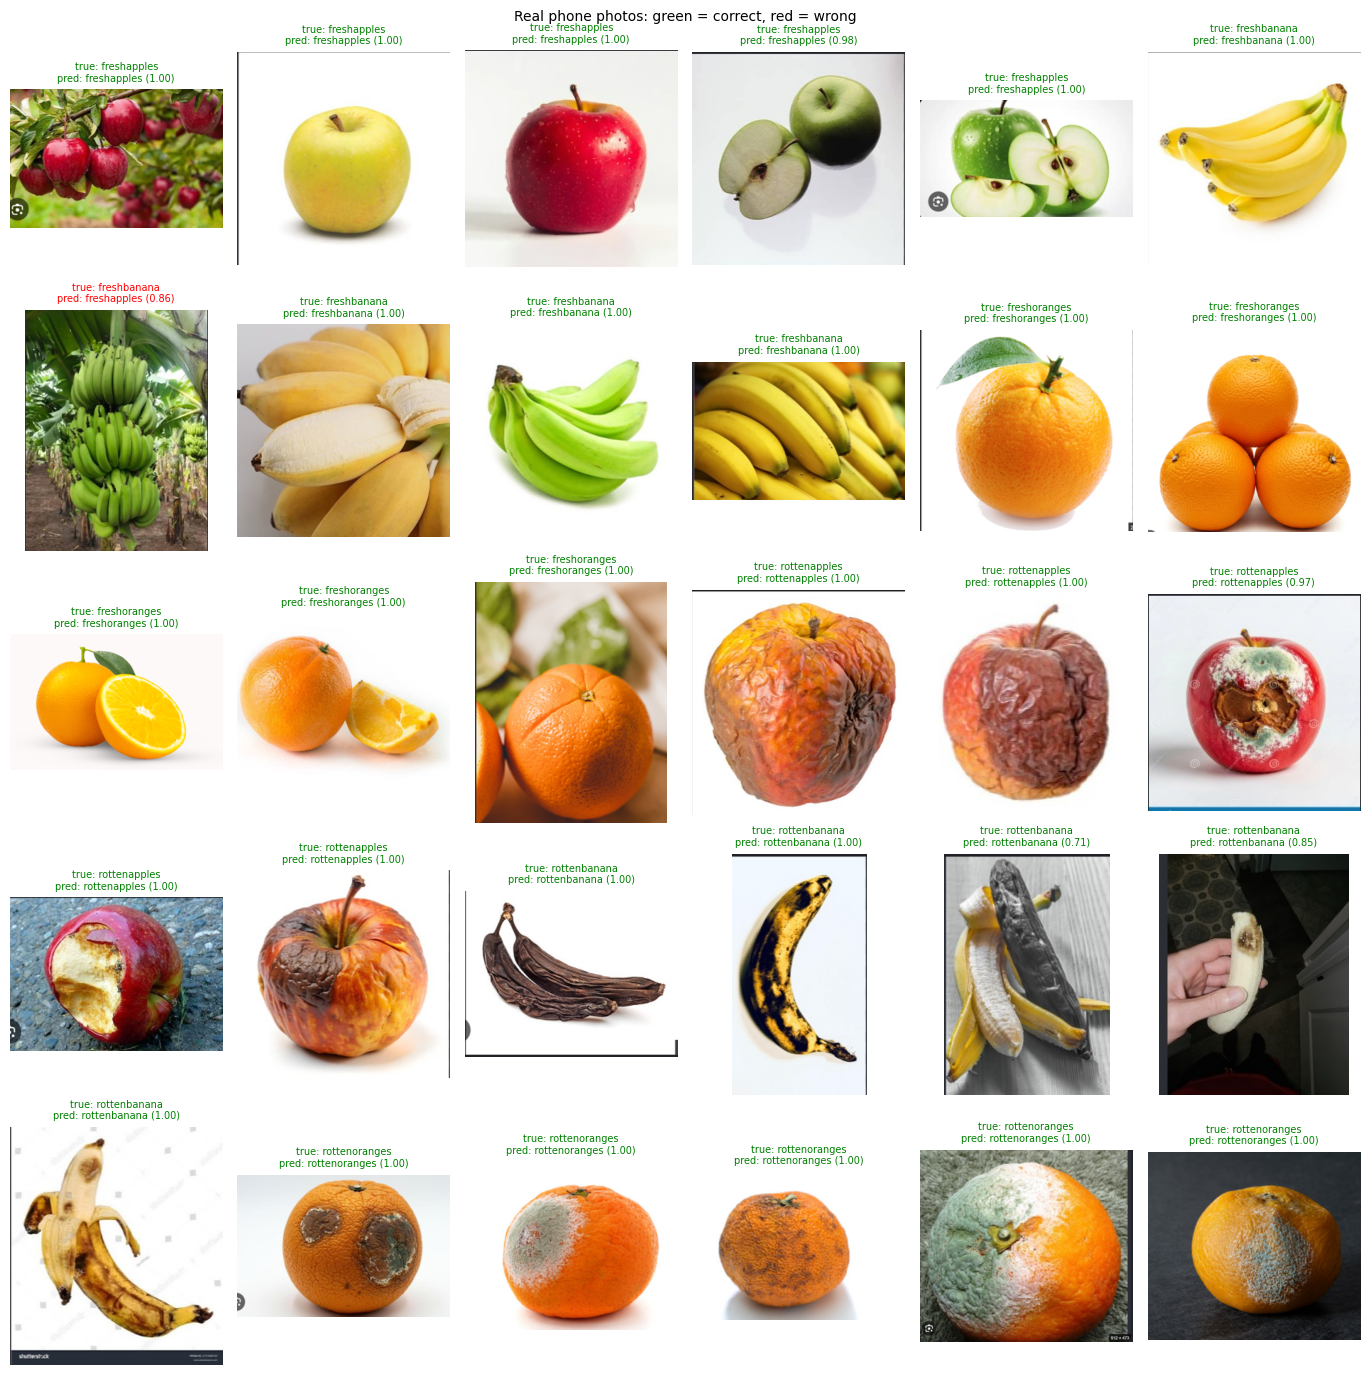

TABLE 3: dataset vs real world


,Evaluation,Images,Accuracy,Rotten recall
0,Dataset test set,2007,0.9950,0.9965
1,Real phone photos,30,0.9667,1.0000


In [29]:
# Prediction grid + the generalisation-gap table
if real_df is not None and len(real_df):
    show = real_df.head(36)
    cols = 6; rows_n = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 2.3, rows_n * 2.8))
    axes = np.array(axes).reshape(-1)
    for a in axes:
        a.axis('off')
    for a, (_, r) in zip(axes, show.iterrows()):
        img = load_photo(r['path']); img.thumbnail((300, 300))
        a.imshow(img)
        a.set_title(f"true: {r['true']}\npred: {r['pred']} ({r['confidence']:.2f})", fontsize=7,
                    color='green' if r['correct'] else 'red')
    plt.suptitle('Real phone photos: green = correct, red = wrong', fontsize=10)
    plt.tight_layout(); plt.savefig(FIG / 'real_photo_predictions.png', dpi=200); plt.show()

    test_json = RES / ('leakfree_test_metrics.json' if FINAL_CKPT == CKPT_LF else 'test_metrics.json')
    tm = json.load(open(test_json)) if test_json.exists() else {}
    gap = pd.DataFrame([
        {'Evaluation': 'Dataset test set', 'Images': tm.get('n_images', tm.get('n_test_images')),
         'Accuracy': tm.get('accuracy', tm.get('test_accuracy')), 'Rotten recall': tm.get('rotten_recall')},
        {'Evaluation': 'Real phone photos', 'Images': m_real['n_images'],
         'Accuracy': round(m_real['accuracy'], 4), 'Rotten recall': round(m_real['rotten_recall'], 4)},
    ])
    gap.to_csv(RES / 'generalisation_gap.csv', index=False)
    print("TABLE 3: dataset vs real world"); display(gap)

# Part D: Explainability

## Step 14: Grad-CAM heatmaps (where does the model look?)
**How Grad-CAM works:** take the gradient of the predicted class score with respect to the last convolutional feature maps (1280 maps of 7×7 in MobileNetV2). Average each gradient map into one importance weight, compute the weighted sum of the maps, keep the positive part, and upscale it to 224×224. **Red areas pushed the model towards its prediction.** (Selvaraju et al., *Grad-CAM*, ICCV 2017.)

**What to look for:**
- ✅ **Good:** red on rotten patches, mould, or the body of the fruit.
- ❌ **Bad (shortcut learning):** red on the background, the image border or random corners.

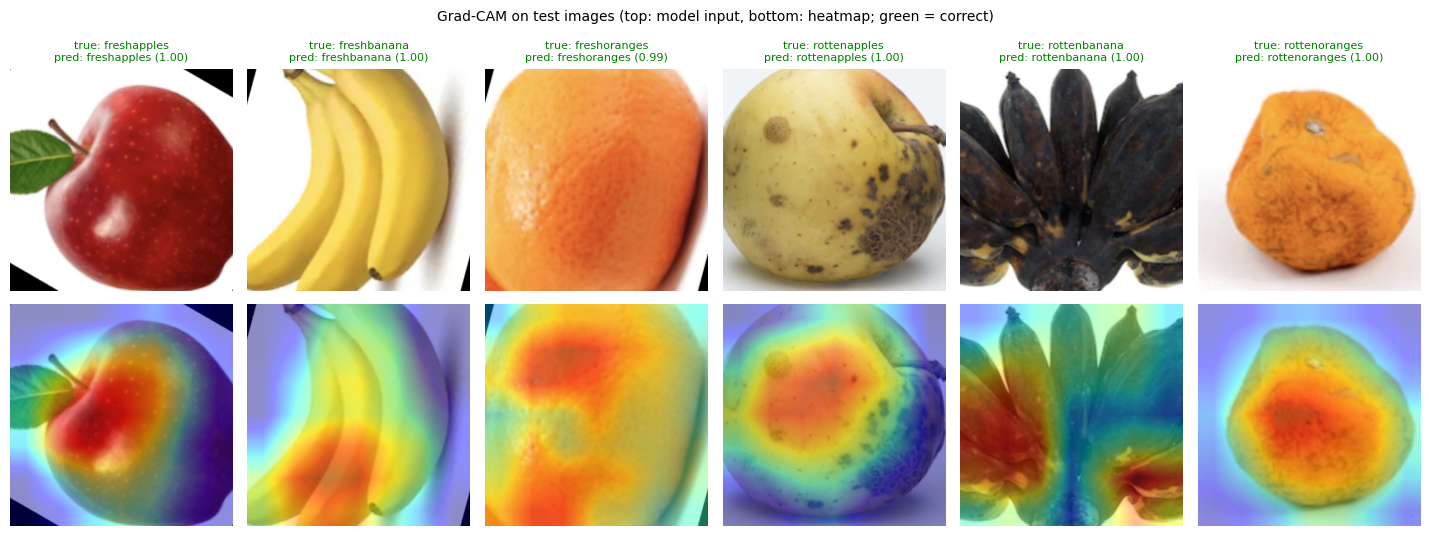

In [30]:
def show_gradcam_grid(samples, title, out_png):
    # samples = [(PIL image, true class name or None), ...]
    n = len(samples)
    fig, axes = plt.subplots(2, n, figsize=(2.4 * n, 5.6))
    axes = np.array(axes).reshape(2, n)
    for j, (img, true) in enumerate(samples):
        probs, pred, cam = gradcam(demo_model, img)
        ok = (true is None) or (true == CLASS_NAMES[pred])
        head = (f"true: {true}\n" if true else "") + f"pred: {CLASS_NAMES[pred]} ({probs[pred]:.2f})"
        axes[0, j].imshow(display_tf(img)); axes[0, j].axis('off')
        axes[0, j].set_title(head, fontsize=8, color='green' if ok else 'red')
        axes[1, j].imshow(overlay_cam(img, cam)); axes[1, j].axis('off')
    plt.suptitle(title, fontsize=10); plt.tight_layout(); plt.savefig(out_png, dpi=200); plt.show()

# One random test image per class
rng_g = random.Random(SEED)
test_pool = splits['test'] if 'splits' in globals() else (
    [(str(p), CLASS_NAMES.index(p.parent.name)) for p in test_files] if 'test_files' in globals() else [])
samples = []
for k, c in enumerate(CLASS_NAMES):
    paths = [p for p, l in test_pool if l == k]
    if paths:
        samples.append((load_photo(rng_g.choice(paths)), c))
if samples:
    show_gradcam_grid(samples, 'Grad-CAM on test images (top: model input, bottom: heatmap; green = correct)', FIG / 'gradcam_test_examples.png')
else:
    print("Test images not loaded (run Steps 3-5 and 8 for this figure). Skipping.")

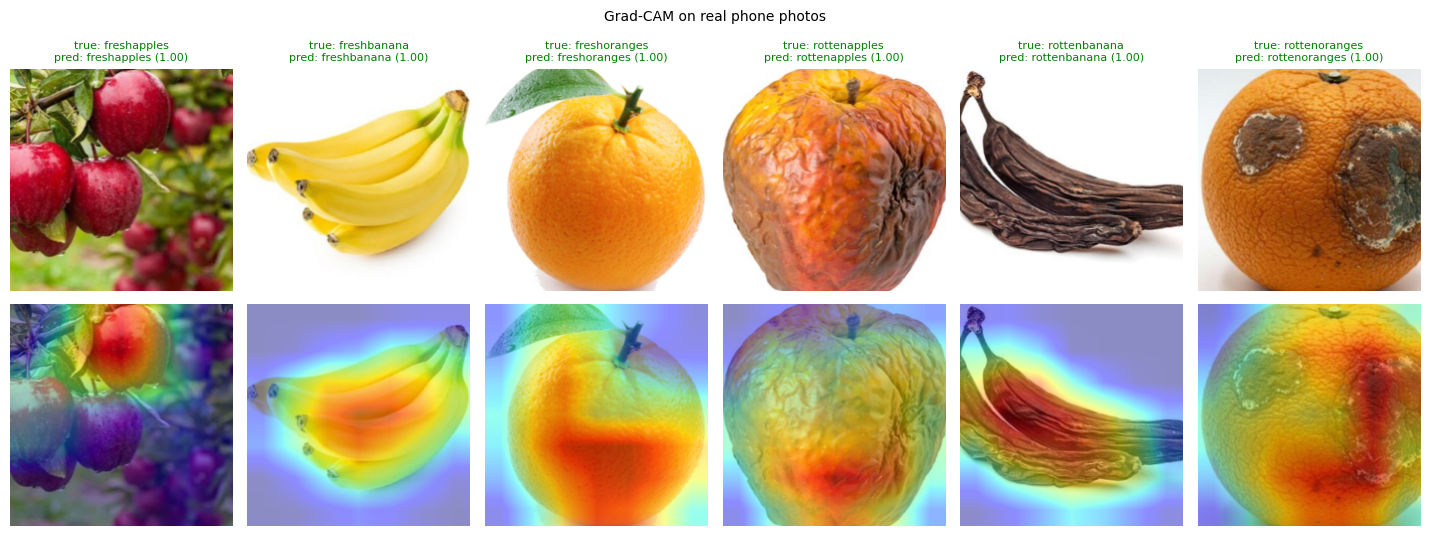

In [31]:
# Grad-CAM on real phone photos (one per class where available, up to 6)
if globals().get('real_items'):
    picked, seen = [], set()
    for p, c in real_items:
        if c not in seen:
            picked.append((load_photo(p), c)); seen.add(c)
    show_gradcam_grid(picked[:6], 'Grad-CAM on real phone photos', FIG / 'gradcam_real_photos.png')
else:
    print("No real photos yet - re-run this cell after Step 13 finds photos.")

# Part E: Demo app

## Step 15: Gradio web app
The app shows the full workflow (*input → preprocessing → prediction → output*):

| Pipeline stage | Where it appears in the app |
|---|---|
| Input | **1.** Upload a photo or take one with the camera |
| Preprocessing | **2.** The 224×224 resized and cropped image the model actually sees |
| Prediction | **3.** Top-3 class probabilities |
| Output | Verdict (🟢 OK to distribute / 🔴 remove / ⚠️ uncertain) + **4.** Grad-CAM heatmap |

**Confidence threshold:** if the model is less than **70%** sure, the app says *"Uncertain, inspect by hand"* instead of guessing. This matters because the model **always** picks one of its 6 classes, even for a mango or a phone (it's a *closed-set* classifier). The threshold is a simple safety net.

The app runs inside the notebook. The same pipeline is hosted permanently as a website at **https://vrxghost.github.io/fruit-freshness/**, using the browser model exported in Step 16.

In [ ]:
import gradio as gr
print("Gradio", gr.__version__)

CONF_THRESHOLD = 0.70
NICE = {c: c.replace('fresh', 'Fresh ').replace('rotten', 'Rotten ') for c in CLASS_NAMES}

def analyse(img):
    if img is None:
        return "Upload or take a photo of **one** apple, banana or orange.", None, None, None
    try:
        try:
            img = ImageOps.exif_transpose(img)
        except Exception:
            pass
        img = img.convert('RGB')
        probs, pred, cam = gradcam(demo_model, img)
        cls, conf = CLASS_NAMES[pred], float(probs[pred])
        if conf < CONF_THRESHOLD:
            verdict = (f"## ⚠️ Uncertain ({conf:.0%} confident)\nPlease inspect this fruit by hand. "
                       "This also happens when the photo is not an apple, banana or orange.")
        elif 'rotten' in cls:
            verdict = f"## 🔴 {NICE[cls]}: remove from supply\nConfidence {conf:.1%}. Not safe to sell or donate."
        else:
            verdict = f"## 🟢 {NICE[cls]}: OK to distribute\nConfidence {conf:.1%}."
        scores = {NICE[c]: float(p) for c, p in zip(CLASS_NAMES, probs)}
        return verdict, scores, display_tf(img), overlay_cam(img, cam)
    except Exception as e:
        return f"## Error\n`{type(e).__name__}: {e}`", None, None, None

# Example images: one test image per class + up to 3 real photos (copied as JPG next to the notebook)
EX_DIR = Path('/content/demo_examples') if Path('/content').exists() else Path('demo_examples')
EX_DIR.mkdir(parents=True, exist_ok=True)
ex_sources, rng_e = [], random.Random(SEED)
if 'splits' in globals():
    for k in range(NUM_CLASSES):
        paths = [p for p, l in splits['test'] if l == k]
        if paths:
            ex_sources.append(rng_e.choice(paths))
if globals().get('real_items'):
    seen = set()
    for p, c in real_items:
        if c not in seen and len(seen) < 3:
            ex_sources.append(p); seen.add(c)
examples = []
for k, src in enumerate(ex_sources):
    dst = EX_DIR / f"example_{k}.jpg"
    try:
        load_photo(src).save(dst, quality=92)
        examples.append([str(dst)])
    except Exception as e:
        print("Skipping example", src, e)

def make_interface(**extra):
    return gr.Interface(
        fn=analyse,
        inputs=gr.Image(type='pil', label='1. Input: upload or take a photo'),
        outputs=[gr.Markdown(),
                 gr.Label(num_top_classes=3, label='3. Prediction (top 3 probabilities)'),
                 gr.Image(label='2. Preprocessed input the model sees (224×224)'),
                 gr.Image(label='4. Grad-CAM: where the model looked')],
        title='🍎 Fruit Freshness Checker',
        description=('Deep learning (MobileNetV2, PyTorch) that classifies apples, bananas and oranges as fresh or rotten. '
                     'Supports SDG 2 (less food waste), SDG 13 (less landfill methane) and SDG 3 (catching spoiled food).'),
        article=('**Limitations:** trained on 3 fruit types only. Any other object is still forced into one of the '
                 '6 classes, so low-confidence results are shown as "Uncertain".'),
        examples=examples or None,
        cache_examples=False,
        **extra)

demo = None
for extra in ({'flagging_mode': 'never'}, {'allow_flagging': 'never'}, {}):
    try:
        demo = make_interface(**extra)
        break
    except TypeError:
        continue

demo.launch(share=False, debug=False, allowed_paths=[str(EX_DIR)])

# Part F: Export for the website

## Step 16: Export the final model to ONNX
**What:** converts the final model (the same one used in Steps 12–15) to **ONNX**, so the website can run it in the browser with ONNX Runtime Web. No server and no GPU are needed, and the photo never leaves the user's device.

The exported model takes a 224×224 `image` and returns two outputs:
- `probs`: the 6 class probabilities
- `cams`: a 7×7 class activation map for each class, used as the heatmap

**Why no gradients are needed in the browser:** the model ends in global average pooling followed by one linear layer. For this kind of head, weighting the last feature maps by the linear layer's weights for a class (CAM) gives the same heatmap as Grad-CAM in Step 14, up to a constant scale. So the browser only needs a forward pass.

A self-check compares the ONNX output with PyTorch on the same input before the files are saved. The `.onnx` file goes into the website's `model/` folder.

In [ ]:
!pip install -q onnx onnxruntime onnxscript
import onnxruntime as ort

# Same final model as Steps 12-15, moved to the CPU for export
web_src, _ = load_model(FINAL_CKPT)
web_src = web_src.cpu().eval()

class WebModel(nn.Module):
    # Outputs class probabilities + a 7x7 heatmap per class.
    # For a pooling + linear head, this CAM equals Grad-CAM (up to scale), so no gradients are needed in the browser.
    def __init__(self, net):
        super().__init__()
        self.features, self.fc = net.features, net.classifier[1]
    def forward(self, x):
        f = self.features(x)                                              # [1, 1280, 7, 7] last conv feature maps
        probs = self.fc(F.adaptive_avg_pool2d(f, 1).flatten(1)).softmax(1)
        cams = F.conv2d(f, self.fc.weight[:, :, None, None])              # [1, 6, 7, 7] one heatmap per class
        return probs, cams

web = WebModel(web_src).eval()
x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
ONNX_PATH = Path('/content/fruit_freshness.onnx') if Path('/content').exists() else Path('fruit_freshness.onnx')
export_args = dict(input_names=['image'], output_names=['probs', 'cams'], opset_version=17)
try:
    torch.onnx.export(web, (x,), str(ONNX_PATH), external_data=False, **export_args)
except Exception as e:
    print('New exporter failed, using the classic one:', e)
    torch.onnx.export(web, (x,), str(ONNX_PATH), dynamo=False, **export_args)

# Self-check: ONNX must give the same answer as PyTorch
p_onnx, c_onnx = ort.InferenceSession(str(ONNX_PATH)).run(None, {'image': x.numpy()})
with torch.no_grad():
    p_t, c_t = web(x)
print('Max difference vs PyTorch:', float(np.abs(p_onnx - p_t.numpy()).max()), '(should be < 0.001)')
print('Model size: %.1f MB' % (ONNX_PATH.stat().st_size / 1e6), '| classes:', CLASS_NAMES)
if CLASS_NAMES != EXPECTED_CLASSES:
    print("⚠️ Class order differs from the website's label list - update CLASSES in index.html to match.")

shutil.copy(ONNX_PATH, MOD / 'fruit_freshness.onnx')
json.dump(CLASS_NAMES, open(MOD / 'class_names.json', 'w'))
print("Saved to Drive:", MOD / 'fruit_freshness.onnx')

try:
    from google.colab import files
    files.download(str(ONNX_PATH))                 # also download a copy for the website's model/ folder
except Exception:
    pass                                           # not on Colab: the file is already saved locally

## Saved outputs
All files are in `MyDrive/fruit_freshness_project/`.

| File | Contents |
|---|---|
| `results/leakage_check.json`, `figures/leakage_example.png` | Leakage analysis |
| `results/leakfree_split_counts.csv` | Leak-free split sizes per class |
| `figures/leakfree_training_curves.png` | Training curves (leak-free split) |
| `results/leakfree_test_metrics.json`, `results/leakfree_classification_report.txt`, `figures/leakfree_confusion_matrix.png` | Final test-set results |
| `results/leakfree_model_comparison.csv` | MobileNetV2 vs custom CNN |
| `results/leakage_effect.csv` | Effect of fixing the leakage |
| `results/real_photo_metrics.json`, `figures/real_photo_predictions.png`, `results/generalisation_gap.csv` | Real-world test |
| `figures/gradcam_test_examples.png`, `figures/gradcam_real_photos.png` | Grad-CAM heatmaps |
| `figures/leakfree_misclassified.png` | Misclassified test images |
| `models/best_mobilenetv2_leakfree.pt` | Final model |
| `models/fruit_freshness.onnx`, `models/class_names.json` | Browser model for the website (`model/fruit_freshness.onnx`) |